# PS-O3 — Resource-Constrained Item Selection (0/1 Knapsack) with QAOA
Qiskit Fall Fest 2026, Phase 2, Optimization Track.

Runs top to bottom with the official settings from `qff_phase2.py` (basis rz/sx/x/cx, optimization_level 1, SABRE, seed_transpiler 42, seed_simulator 42, 4096 shots, official noise). Seeds used: initializations 0–4 (`numpy.random.default_rng`), transpiler/simulator 42.

Set `RECOMPUTE_LANDSCAPE = False` to reload the saved landscape instead of recomputing it.

In [22]:
import sys, json, time, itertools, csv
sys.path.insert(0, "src")
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector
from qff_phase2 import (PROCESSOR_A, PROCESSOR_B, SHOTS, load_processor, validate_processor_d,
                        circuit_metrics, transpile_for, simulator, bell_experiment, counts_to_x,
                        coupling_map_from_edges)
from knapsack import (load_instance, build_qubo, qubo_energy, qubo_to_hamiltonian, pauli_scale,
                      qaoa_circuit, bind, optimize, classical, evaluate_counts)

RECOMPUTE_LANDSCAPE = True
SEEDS = [0, 1, 2, 3, 4]
T0 = time.time()
import qiskit, qiskit_aer
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| python", sys.version.split()[0])

qiskit 2.6.1 | qiskit-aer 0.18.2 | python 3.13.14


## 1. Formulation

Items i = 0..4 (item n in the PS is qubit n−1), values v = [10, 4, 7, 5, 8], weights w = [5, 3, 4, 2, 6], capacity W = 15.
The inequality Σ wᵢxᵢ ≤ 15 becomes an equality with binary slack s = s₀ + 2s₁ + 4s₂ + 8s₃ on qubits 5–8 (range 0–15). With penalty P = 5:

$$\min_{x,s}\; -\sum_i v_i x_i + P\Big(\sum_i w_i x_i + s_0 + 2s_1 + 4s_2 + 8s_3 - 15\Big)^2$$

Write all nine binary variables as z with coefficients a = [5, 3, 4, 2, 6, 1, 2, 4, 8]. Expanding the square and using zᵢ² = zᵢ gives an upper-triangular QUBO zᵀQz + 225 with

- Qᵢᵢ = P(aᵢ² − 30aᵢ) − vᵢ (vᵢ = 0 for slack bits)
- Qᵢⱼ = 2P·aᵢaⱼ for i < j.

Every pair of variables is coupled (all aᵢ > 0), so the cost graph is the complete graph K₉ with 36 edges.

In [23]:
v, w, W, P = load_instance()
Q, c0 = build_qubo(v, w, W, P)
np.set_printoptions(linewidth=140)
print("9x9 QUBO (upper triangular), constant =", c0)
print(Q.astype(int))
json.dump({"Q": Q.tolist(), "constant": c0}, open("results/tables/qubo_9x9.json", "w"), indent=1)

9x9 QUBO (upper triangular), constant = 1125
[[-635  150  200  100  300   50  100  200  400]
 [   0 -409  120   60  180   30   60  120  240]
 [   0    0 -527   80  240   40   80  160  320]
 [   0    0    0 -285  120   20   40   80  160]
 [   0    0    0    0 -728   60  120  240  480]
 [   0    0    0    0    0 -145   20   40   80]
 [   0    0    0    0    0    0 -280   80  160]
 [   0    0    0    0    0    0    0 -520  320]
 [   0    0    0    0    0    0    0    0 -880]]


In [24]:
cl = classical(v, w, W)
allz = list(itertools.product([0, 1], repeat=9))
zmin = min(allz, key=lambda z: qubo_energy(z, Q, c0))
print("Exhaustive search over 32 item subsets:")
print("  V* =", cl["V_star"], "| optimal subset (x0..x4) =", cl["opt_subsets"], "| weight =", int(np.dot(w, cl["opt_subsets"][0])))
print("  feasible subsets:", cl["n_feasible"], "/", cl["n_subsets"], "-> random P_feasible =", cl["P_feasible_random"])
print("  random P_opt (item bits) =", cl["P_opt_random"])
print("QUBO brute force over 512 bitstrings: min energy", qubo_energy(zmin, Q, c0), "at items", zmin[:5], "slack", zmin[5:],
      "(s =", sum(b * 2**k for k, b in enumerate(zmin[5:])), ")")
assert qubo_energy(zmin, Q, c0) == -cl["V_star"]

Exhaustive search over 32 item subsets:
  V* = 26 | optimal subset (x0..x4) = [(1, 1, 1, 1, 0)] | weight = 14
  feasible subsets: 28 / 32 -> random P_feasible = 0.875
  random P_opt (item bits) = 0.03125
QUBO brute force over 512 bitstrings: min energy -26.0 at items (1, 1, 1, 1, 0) slack (1, 0, 0, 0) (s = 1 )


## 2. Cost Hamiltonian and scaling

Substituting zᵢ = (1 − Zᵢ)/2 gives H = Σ hᵢZᵢ + Σ Jᵢⱼ ZᵢZⱼ + const. The diagonal of H is checked against the QUBO on all 512 bitstrings.
The coefficients are large (|J| up to 120), so the useful γ region is tiny. As the kit recommends, we divide H by its largest non-identity Pauli coefficient; all QAOA angles below refer to the scaled Hamiltonian H/scale.

In [25]:
H = qubo_to_hamiltonian(Q, c0)
scale = pauli_scale(H)
Hs = H / scale
d = np.real(H.to_matrix(sparse=True).diagonal())
ok = all(abs(d[int("".join(map(str, z[::-1])), 2)] - qubo_energy(z, Q, c0)) < 1e-9 for z in allz)
print("Pauli terms:", len(H), "| diagonal matches QUBO:", ok, "| scale =", scale)

Pauli terms: 46 | diagonal matches QUBO: True | scale = 120.0


## 3. Processor D (Objective 2)

The bottleneck on Processor B is routing: the knapsack cost graph is K₉, but B has diameter 4 and an uneven degree profile (qubit 6 has degree 5, qubit 7 degree 1). Processor D is a **3×3 torus**: 9 qubits, every qubit has degree 4 (the maximum allowed), and the wrap-around edges give diameter 2. A graph search over valid degree-4 candidates (circulants and random 4-regular graphs on 9–12 qubits, 3×4/2×5/2×6 tori) found no design with fewer CX for this circuit.

Processor D rule check: OK
B edges 12 | diameter 4 | degrees [1, 2, 2, 2, 2, 3, 3, 4, 5]
D edges 18 | diameter 2 | degrees [4, 4, 4, 4, 4, 4, 4, 4, 4]


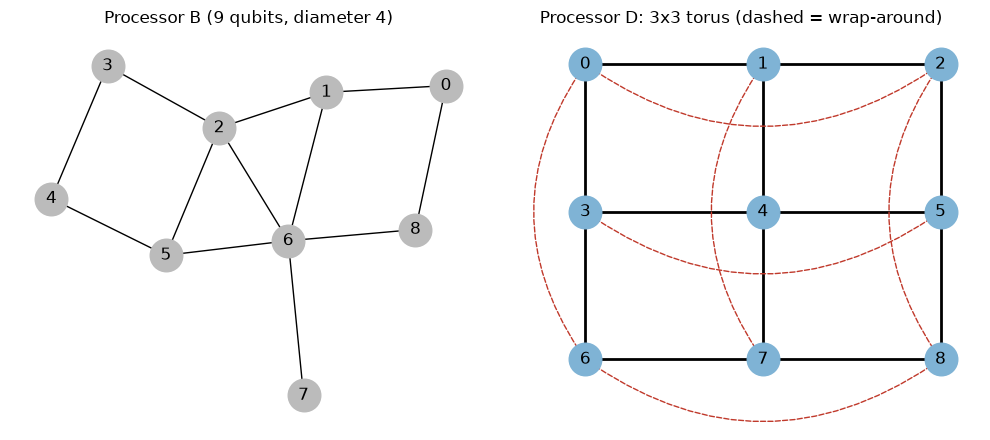

In [26]:
D = load_processor("processors/processor_D.json")
print("Processor D rule check:", validate_processor_d(D, required_qubits=9) or "OK")
gD, gB = nx.Graph(D["edges"]), nx.Graph(PROCESSOR_B["edges"])
for name, g in (("B", gB), ("D", gD)):
    print(name, "edges", g.number_of_edges(), "| diameter", nx.diameter(g), "| degrees", sorted(dict(g.degree()).values()))
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
nx.draw(gB, nx.kamada_kawai_layout(gB), ax=ax[0], with_labels=True, node_color="#bbb", node_size=550)
ax[0].set_title("Processor B (9 qubits, diameter 4)")
pos = {r * 3 + c: (c, -r) for r in range(3) for c in range(3)}
straight = [e for e in gD.edges() if abs(pos[e[0]][0] - pos[e[1]][0]) + abs(pos[e[0]][1] - pos[e[1]][1]) == 1]
wrap = [e for e in gD.edges() if e not in straight]
nx.draw_networkx_nodes(gD, pos, ax=ax[1], node_color="#7fb3d5", node_size=550)
nx.draw_networkx_labels(gD, pos, ax=ax[1])
nx.draw_networkx_edges(gD, pos, edgelist=straight, ax=ax[1], width=2)
nx.draw_networkx_edges(gD, pos, edgelist=wrap, ax=ax[1], style="dashed", edge_color="#c0392b", connectionstyle="arc3,rad=0.35", arrows=True, arrowstyle="-")
ax[1].set_title("Processor D: 3x3 torus (dashed = wrap-around)"); ax[1].axis("off")
plt.tight_layout(); plt.savefig("results/figures/processors_B_D.png", dpi=150); plt.show()

## 4. Bell-state verification on Processor D (Objective 1)

|Φ⁺⟩ = (|00⟩ + |11⟩)/√2 via H(0), CX(0→1), measured in ZZ, XX (H⊗H) and YY (S†⊗S† then H⊗H), 4096 shots each.
Fidelity F = (1 + ⟨XX⟩ − ⟨YY⟩ + ⟨ZZ⟩)/4. Pairs: an adjacent pair (0, 1) and a farthest pair. On the torus the diameter is 2, so (0, 4) is a farthest pair.

In [27]:
cmD = coupling_map_from_edges(D["edges"], D["num_qubits"])
far = max(((a, b) for a in range(9) for b in range(a + 1, 9)), key=lambda p: cmD.distance(*p))
bell_rows = []
for pair in [(0, 1), far]:
    for noisy in (False, True):
        r = bell_experiment(D, pair, noisy)
        bell_rows.append({"pair": f"{pair[0]}-{pair[1]}", "pair_distance": r["pair_distance"],
                          "condition": "noisy" if noisy else "ideal", "cx": r["cx"],
                          "XX": round(r["XX"], 4), "XX_se": round(r["XX_se"], 4),
                          "YY": round(r["YY"], 4), "YY_se": round(r["YY_se"], 4),
                          "ZZ": round(r["ZZ"], 4), "ZZ_se": round(r["ZZ_se"], 4),
                          "fidelity": round(r["fidelity"], 4), "fidelity_se": round(r["fidelity_se"], 4), "shots": SHOTS})
with open("results/tables/bell.csv", "w", newline="") as f:
    wr = csv.DictWriter(f, fieldnames=bell_rows[0].keys()); wr.writeheader(); wr.writerows(bell_rows)
for r in bell_rows:
    print(f"{r['pair']:>4} d={r['pair_distance']} {r['condition']:5} CX={r['cx']}  XX={r['XX']:+.3f}±{r['XX_se']:.3f}  "
          f"YY={r['YY']:+.3f}±{r['YY_se']:.3f}  ZZ={r['ZZ']:+.3f}±{r['ZZ_se']:.3f}  F={r['fidelity']:.4f}±{r['fidelity_se']:.4f}")

 0-1 d=1 ideal CX=1  XX=+1.000±0.000  YY=-1.000±0.000  ZZ=+1.000±0.000  F=1.0000±0.0000
 0-1 d=1 noisy CX=1  XX=+0.946±0.005  YY=-0.952±0.005  ZZ=+0.955±0.005  F=0.9633±0.0021
 0-4 d=2 ideal CX=4  XX=+1.000±0.000  YY=-1.000±0.000  ZZ=+1.000±0.000  F=1.0000±0.0000
 0-4 d=2 noisy CX=4  XX=+0.945±0.005  YY=-0.936±0.005  ZZ=+0.939±0.005  F=0.9548±0.0023


## 5. QAOA p = 1 (Objective 3)

Circuit: H on all 9 qubits, cost layer exp(−iγ H/scale) as 36 RZZ + 9 RZ, mixer RX(2β) on every qubit.
Optimizer: **COBYLA** (scipy), maxiter 200, cost = exact statevector expectation of H/scale (no shots, no noise). Five initializations with `default_rng(seed)`, seeds 0–4, γ and β uniform in [0, π]. Following the kit FAQ, angles are optimized once in ideal simulation and the same angles are evaluated on every processor.

In [28]:
t = time.time()
runs = optimize(Hs, seeds=SEEDS, p=1, maxiter=200)
print(f"optimization time {time.time() - t:.1f}s")
for r in runs:
    print(f"seed {r['seed']}: start (g,b)=({r['x0'][0]:.3f},{r['x0'][1]:.3f}) -> ({r['theta'][0]:.4f},{r['theta'][1]:.4f})  "
          f"<H/scale>={r['cost']:.4f}  <H>={r['cost'] * scale:.2f}  evals={r['nfev']}")
best = min(runs, key=lambda r: r["cost"])
theta = best["theta"]
print("best seed", best["seed"], "theta", theta)
json.dump({"runs": runs, "best_seed": best["seed"], "theta": theta, "scale": scale}, open("results/tables/qaoa_runs.json", "w"), indent=1)

optimization time 6.1s
seed 0: start (g,b)=(2.001,0.848) -> (2.3823,1.5157)  <H/scale>=1.9321  <H>=231.86  evals=200
seed 1: start (g,b)=(1.608,2.986) -> (0.2831,2.8647)  <H/scale>=0.4185  <H>=50.22  evals=83
seed 2: start (g,b)=(0.822,0.938) -> (3.0158,3.0877)  <H/scale>=1.9359  <H>=232.31  evals=145
seed 3: start (g,b)=(0.269,0.744) -> (0.2845,1.3544)  <H/scale>=1.0882  <H>=130.58  evals=78
seed 4: start (g,b)=(2.963,1.606) -> (4.0603,1.5992)  <H/scale>=1.9409  <H>=232.91  evals=83
best seed 1 theta [0.2830525948343897, 2.8647378514604878]


In [29]:
qc, gs, bs = qaoa_circuit(Hs, p=1, measure=True)
bq = bind(qc, gs, bs, theta)
with open("results/figures/qaoa_circuit.txt", "w", encoding="utf-8") as f:
    f.write(str(bq.draw("text", fold=200)))
print(qc.draw("text", fold=120, idle_wires=False).__str__()[:2500])
print(bq.count_ops())

        ┌───┐                                                                                                  »
   q_0: ┤ H ├─■──────────────■───────────────────────────■────────────────────────────────────────■────────────»
        ├───┤ │ZZ(0.625*g0)  │                           │                                        │            »
   q_1: ┤ H ├─■──────────────┼───────────────────────────┼───────────────────────────■────────────┼────────────»
        ├───┤                │ZZ(0.8333333333333334*g0)  │                           │ZZ(0.5*g0)  │            »
   q_2: ┤ H ├────────────────■───────────────────────────┼───────────────────────────■────────────┼────────────»
        ├───┤                                            │ZZ(0.4166666666666667*g0)               │            »
   q_3: ┤ H ├────────────────────────────────────────────■────────────────────────────────────────┼────────────»
        ├───┤                                                                                   

### Consistency across initializations (ideal statevector, exact)
For each seed's optimized angles we compute exact P_feasible, P_opt and the probability of the optimal subset from the statevector.

In [30]:
def exact_quality(th):
    probs = Statevector(bind(*qaoa_circuit(Hs)[:3], th)).probabilities_dict()
    pf = sum(p for k, p in probs.items() if np.dot(w, counts_to_x(k)[:5]) <= W)
    po = sum(p for k, p in probs.items() if counts_to_x(k)[:5] in cl["opt_subsets"])
    return pf, po
cons = []
for r in runs:
    pf, po = exact_quality(r["theta"]); cons.append((r["seed"], pf, po))
    print(f"seed {r['seed']}: P_feasible={pf:.4f}  P_opt={po:.4f}")
pfs = np.array([c[1] for c in cons]); pos_ = np.array([c[2] for c in cons])
print(f"mean ± std over seeds: P_feasible {pfs.mean():.4f} ± {pfs.std():.4f} | P_opt {pos_.mean():.4f} ± {pos_.std():.4f}")
print("random baseline: P_feasible", cl["P_feasible_random"], "| P_opt", cl["P_opt_random"])

seed 0: P_feasible=0.8736  P_opt=0.0318
seed 1: P_feasible=0.9554  P_opt=0.0226
seed 2: P_feasible=0.8759  P_opt=0.0317
seed 3: P_feasible=0.8916  P_opt=0.0393
seed 4: P_feasible=0.8751  P_opt=0.0311
mean ± std over seeds: P_feasible 0.8943 ± 0.0312 | P_opt 0.0313 ± 0.0053
random baseline: P_feasible 0.875 | P_opt 0.03125


## 6. Benchmark on Processors A, B and D, ideal and noisy (4096 shots)
Processor A has 5 qubits and the QUBO needs 9, so by the capacity rule it is reported as not executable. It cannot even hold the 5 item bits plus any slack, so no valid encoding of this instance fits on A.

In [31]:
procs = {"A": PROCESSOR_A, "B": PROCESSOR_B, "D": D}
rows, quality = [], []
metrics = {}
for name, proc in procs.items():
    m = circuit_metrics(bq, proc); metrics[name] = m
    for cond in ("ideal", "noisy"):
        if not m["executable"]:
            rows.append({"problem_id": "PS-O3", "processor": name, "condition": cond, "executable": "false",
                         "logical_qubits": 9, "physical_qubits": proc["num_qubits"]})
            continue
        tq = transpile_for(bq, proc)
        counts = simulator(cond == "noisy", proc).run(tq, shots=SHOTS).result().get_counts()
        e = evaluate_counts(counts, v, w, W, cl["opt_subsets"], Q, c0)
        pct = 100 * e["best_feasible_value"] / cl["V_star"]
        quality.append({"processor": name, "condition": cond, **{k: e[k] for k in ("P_feasible", "P_opt", "best_feasible_value", "best_weight")},
                        "best_items": "".join(map(str, e["best_items"])), "pct_optimal": pct, "mean_qubo_energy": e["mean_qubo_energy"]})
        rows.append({"problem_id": "PS-O3", "processor": name, "condition": cond, "executable": "true",
                     **{k: m[k] for k in ("logical_qubits", "physical_qubits", "logical_cx", "cx", "depth", "two_q_depth", "swaps", "cx_overhead")},
                     "shots": SHOTS, "quality_metric": "P_feasible", "quality_value": round(e["P_feasible"], 4),
                     "p_opt": round(e["P_opt"], 4), "classical_optimum": cl["V_star"], "random_baseline": cl["P_feasible_random"]})
cols = ["problem_id","processor","condition","executable","logical_qubits","physical_qubits","logical_cx","cx","depth",
        "two_q_depth","swaps","cx_overhead","shots","quality_metric","quality_value","p_opt","classical_optimum","random_baseline"]
with open("results/tables/results.csv", "w", newline="") as f:
    wr = csv.DictWriter(f, fieldnames=cols, restval=""); wr.writeheader(); wr.writerows(rows)
with open("results/tables/quality.csv", "w", newline="") as f:
    wr = csv.DictWriter(f, fieldnames=quality[0].keys()); wr.writeheader(); wr.writerows(quality)
print("Resources (bound p=1 circuit with measurements):")
for name, m in metrics.items():
    print(" ", name, "not executable: needs 9 qubits, has 5" if not m["executable"] else
          f"logical_cx={m['logical_cx']} cx={m['cx']} depth={m['depth']} 2q_depth={m['two_q_depth']} swaps={m['swaps']} overhead={m['cx_overhead']}")
print("\nQuality:")
for q in quality:
    print(f"  {q['processor']} {q['condition']:5}  P_feasible={q['P_feasible']:.4f}  P_opt={q['P_opt']:.4f}  best={q['best_feasible_value']} "
          f"(items {q['best_items']}, weight {q['best_weight']})  %opt={q['pct_optimal']:.1f}  <QUBO>={q['mean_qubo_energy']:.1f}")
print("random baseline P_feasible =", cl["P_feasible_random"], "| P_opt =", cl["P_opt_random"])

Resources (bound p=1 circuit with measurements):
  A not executable: needs 9 qubits, has 5
  B logical_cx=72 cx=121 depth=117 2q_depth=79 swaps=17 overhead=49
  D logical_cx=72 cx=89 depth=76 2q_depth=43 swaps=9 overhead=17

Quality:
  B ideal  P_feasible=0.9590  P_opt=0.0210  best=26 (items 11110, weight 14)  %opt=100.0  <QUBO>=48.9
  B noisy  P_feasible=0.9431  P_opt=0.0249  best=26 (items 11110, weight 14)  %opt=100.0  <QUBO>=82.9
  D ideal  P_feasible=0.9563  P_opt=0.0229  best=26 (items 11110, weight 14)  %opt=100.0  <QUBO>=52.0
  D noisy  P_feasible=0.9434  P_opt=0.0225  best=26 (items 11110, weight 14)  %opt=100.0  <QUBO>=73.5
random baseline P_feasible = 0.875 | P_opt = 0.03125


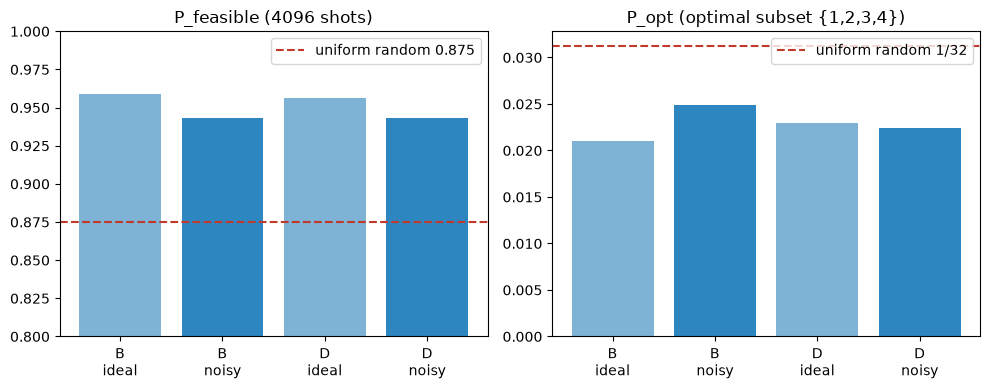

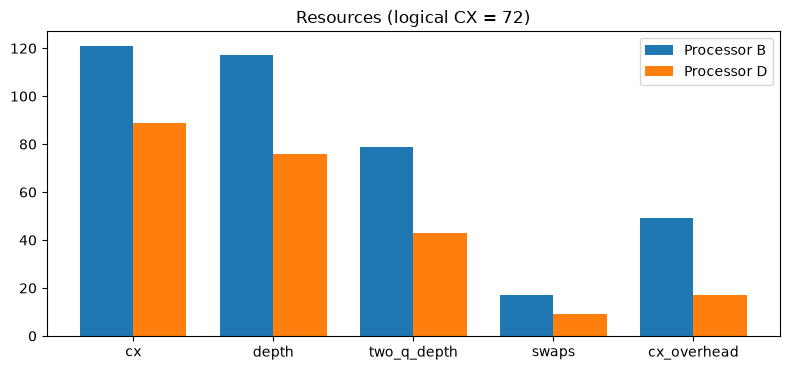

In [32]:
labels = [f"{q['processor']}\n{q['condition']}" for q in quality]
x = np.arange(len(quality))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(x, [q["P_feasible"] for q in quality], color=["#7fb3d5" if q["condition"] == "ideal" else "#2e86c1" for q in quality])
ax[0].axhline(cl["P_feasible_random"], color="#c0392b", ls="--", label="uniform random 0.875")
ax[0].set_ylim(0.8, 1.0); ax[0].set_xticks(x, labels); ax[0].set_title("P_feasible (4096 shots)"); ax[0].legend()
ax[1].bar(x, [q["P_opt"] for q in quality], color=["#7fb3d5" if q["condition"] == "ideal" else "#2e86c1" for q in quality])
ax[1].axhline(cl["P_opt_random"], color="#c0392b", ls="--", label="uniform random 1/32")
ax[1].set_xticks(x, labels); ax[1].set_title("P_opt (optimal subset {1,2,3,4})"); ax[1].legend()
plt.tight_layout(); plt.savefig("results/figures/quality_vs_random.png", dpi=150); plt.show()

names = [n for n in ("B", "D")]
keys = ["cx", "depth", "two_q_depth", "swaps", "cx_overhead"]
fig, ax = plt.subplots(figsize=(8, 3.8)); wd = 0.38
for k, n in enumerate(names):
    ax.bar(np.arange(len(keys)) + (k - 0.5) * wd, [metrics[n][kk] for kk in keys], wd, label=f"Processor {n}")
ax.set_xticks(np.arange(len(keys)), keys); ax.set_title(f"Resources (logical CX = {metrics['B']['logical_cx']})"); ax.legend()
plt.tight_layout(); plt.savefig("results/figures/resources_B_D.png", dpi=150); plt.show()

## 7. Objective landscape on Processor D, official noise
Grid 20 × 20: β ∈ [0, π], γ ∈ [0, γ_max] with **γ_max = 1.0 in units of H/scale** (scale = 120, i.e. γ_max = 1/120 for the unscaled H). A coarse ideal scan showed all structure lies at γ < 1; beyond that the cost layer scrambles phases and the landscape flattens. Value plotted: sampled mean of the (unscaled) QUBO cost, 1024 shots per point, noisy simulation on D. The optimized (γ, β) is marked.

landscape computed in 35.5s
grid minimum <QUBO> = 66.6 at gamma=0.263, beta=2.811


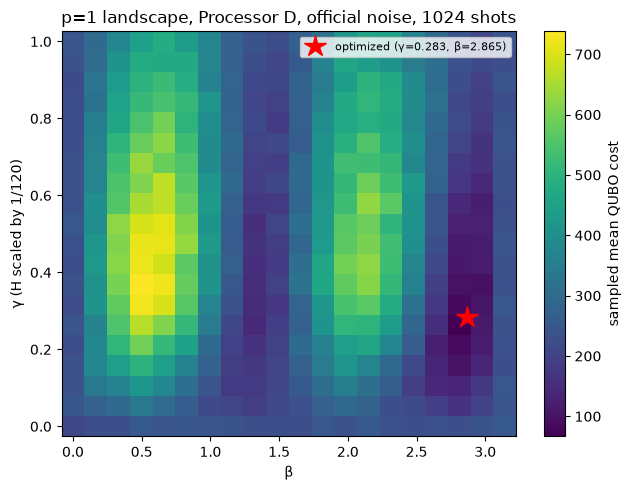

In [33]:
G = np.linspace(0, 1.0, 20); Bt = np.linspace(0, np.pi, 20)
if RECOMPUTE_LANDSCAPE:
    t = time.time()
    tpl = transpile_for(qc, D)
    sim = simulator(True, D)
    circs = [tpl.assign_parameters({gs[0]: g, bs[0]: b}) for g in G for b in Bt]
    res = sim.run(circs, shots=1024).result()
    L = np.array([evaluate_counts(res.get_counts(i), v, w, W, cl["opt_subsets"], Q, c0)["mean_qubo_energy"]
                  for i in range(len(circs))]).reshape(len(G), len(Bt))
    np.savez("results/tables/landscape_D_noisy.npz", G=G, B=Bt, L=L)
    print(f"landscape computed in {time.time() - t:.1f}s")
else:
    z = np.load("results/tables/landscape_D_noisy.npz"); G, Bt, L = z["G"], z["B"], z["L"]
i, j = np.unravel_index(L.argmin(), L.shape)
print(f"grid minimum <QUBO> = {L.min():.1f} at gamma={G[i]:.3f}, beta={Bt[j]:.3f}")
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.pcolormesh(Bt, G, L, shading="auto", cmap="viridis"); plt.colorbar(im, label="sampled mean QUBO cost")
ax.plot(theta[1] % np.pi, theta[0], "r*", ms=16, label=f"optimized (γ={theta[0]:.3f}, β={theta[1]:.3f})")
ax.set_xlabel("β"); ax.set_ylabel("γ (H scaled by 1/120)"); ax.set_title("p=1 landscape, Processor D, official noise, 1024 shots"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig("results/figures/landscape_D_noisy.png", dpi=150); plt.show()

## 8. Best solution

Selected items (PS numbering): [1, 2, 3, 4] | value 26 | weight 14 / 15 | V* = 26


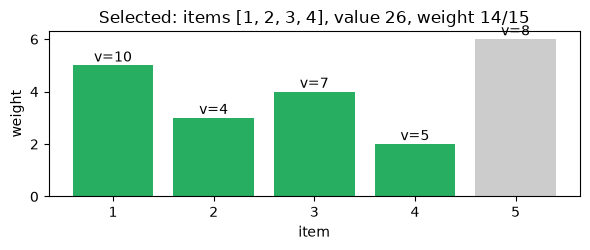

total notebook time 46.2s


In [34]:
qD = [q for q in quality if q["processor"] == "D" and q["condition"] == "noisy"][0]
items = [k + 1 for k, b in enumerate(qD["best_items"]) if b == "1"]
print("Selected items (PS numbering):", items, "| value", qD["best_feasible_value"], "| weight", qD["best_weight"], "/", W, "| V* =", cl["V_star"])
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(range(1, 6), w, color=["#27ae60" if k + 1 in items else "#ccc" for k in range(5)])
for k in range(5): ax.text(k + 1, w[k] + 0.15, f"v={v[k]}", ha="center")
ax.set_xlabel("item"); ax.set_ylabel("weight"); ax.set_title(f"Selected: items {items}, value {qD['best_feasible_value']}, weight {qD['best_weight']}/15")
plt.tight_layout(); plt.savefig("results/figures/selected_items.png", dpi=150); plt.show()
print(f"total notebook time {time.time() - T0:.1f}s")